# Hospital Patient Intelligence & Care Analytics Pipeline

Single-Source End-to-End Data Engineering Workflow

Primary Data Source: hospital_patient_care_entire_dataset.csv

This project implements an end-to-end healthcare analytics pipeline using a single integrated CSV dataset. The dataset brings together multiple hospital data domains into one analytical source, enabling patient-level analysis, operational monitoring, and synthetic risk assessment.

Integrated Data Domains

The dataset consolidates:

 Patient Registration — demographics and patient details
 Appointment Records — scheduling, waiting time, and visit information
 Laboratory Reports — test results and diagnostic measurements
 Wearable / IoT Data — heart rate, temperature, oxygen levels, and other readings
 Doctor Consultations — consultation details and clinical observations
 Synthetic Risk Indicators — generated labels for analytics and model demonstration
 End-to-End Pipeline
                  Hospital Data
                        │
                        ▼
           Single CSV Landing Layer
                        │
                        ▼
               Data Quality Checks
                        │
                        ▼
            Cleaning & Standardization
                        │
                        ▼
               Patient 360 View
                        │
                        ▼
              KPI & Trend Analytics
                        │
                        ▼
              Visual Analytics
                        │
                        ▼
           Synthetic Risk Assessment
                        │
                        ▼
             Management Insights
 Key Objectives

The pipeline is designed to demonstrate how hospital data can be transformed from raw records into actionable insights by:

Improving data consistency and reliability
Creating a unified Patient 360° view
Measuring operational and patient-care KPIs
Identifying trends and unusual patterns
Demonstrating a synthetic high-risk prediction workflow
Supporting data-driven hospital management decisions
 Project Flow

Raw Data → Quality → Transformation → Integration → Analytics → Prediction → Insights

⚠️ Educational Use Only: All patient records and risk labels in this project are synthetically generated. The prediction component is intended solely to demonstrate data engineering, analytics, and machine-learning concepts. It must not be used for medical diagnosis, treatment decisions, or real-world clinical risk assessment.

## 1. Production Architecture

```text
Registration ─┐
Appointments ─┤
Lab System ───┤
Wearables ────┼──► Kafka/Kinesis/API/Batch
Doctor EMR ───┘             │
                            ▼
                      Data Lake / Raw
                            │
                            ▼
                    Spark / ETL / ELT
                            │
                            ▼
                    Curated Warehouse
                            │
                 ┌──────────┴─────────┐
                 ▼                    ▼
             BI Dashboard          ML Pipeline
```

For this academic implementation, the separate source systems are represented as event records inside one CSV so the entire project can be shared as a single dataset.


In [7]:
import pandas as pd
import numpy as np

# Load dataset
DATA_FILE = r"C:\Users\chind\OneDrive\Documents\NEW CASE\hospital_management_full_dataset.csv"

df = pd.read_csv(DATA_FILE)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (50, 20)

Columns:
['patient_id', 'name', 'age', 'age_group', 'gender', 'department', 'appointment_id', 'appointment_date', 'arrival_time', 'consultation_time', 'waiting_time_min', 'hemoglobin_result', 'heart_rate', 'steps', 'diagnosis', 'doctor_name', 'doctor_note', 'patient_type', 'appointment_status', 'treatment_plan']


,patient_id,name,age,age_group,gender,department,appointment_id,appointment_date,arrival_time,consultation_time,waiting_time_min,hemoglobin_result,heart_rate,steps,diagnosis,doctor_name,doctor_note,patient_type,appointment_status,treatment_plan
0,P001,Ananya Rao,45,Adult,Female,Cardiology,A001,2026-09-15,09:00,09:35,35,13.2,82,4200,Hypertension,Dr. Mehta,Routine follow-up,Outpatient,Completed,Prescription updated
1,P002,Arjun Kumar,32,Young Adult,Male,General Medicine,A002,2026-09-15,09:10,09:25,15,14.1,76,6500,Viral fever,Dr. Reddy,Stable condition,Outpatient,Completed,Continue medication
2,P003,Meera Nair,67,Elderly,Female,Cardiology,A003,2026-09-15,09:20,10:15,55,10.2,98,1800,Heart failure,Dr. Sharma,Needs additional observation,Inpatient,Observation,ECG recommended
3,P004,Vikram Singh,51,Senior,Male,Orthopedics,A004,2026-09-15,09:30,10:00,30,15.0,88,5200,Osteoarthritis,Dr. Kapoor,Knee pain,Outpatient,Completed,Physiotherapy advised
4,P005,Sneha Iyer,29,Young Adult,Female,Dermatology,A005,2026-09-15,09:40,10:05,25,12.8,72,8400,Dermatitis,Dr. Joseph,Skin irritation,Outpatient,Completed,Topical treatment prescribed


In [8]:
# ============================================================
# PATIENT 360 DATASET
# ============================================================

patient_360 = df.copy()

# ------------------------------------------------------------
# Clean column names
# ------------------------------------------------------------

patient_360.columns = (
    patient_360.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

# ------------------------------------------------------------
# Convert numeric columns
# ------------------------------------------------------------

numeric_columns = [
    "age",
    "waiting_time_min",
    "hemoglobin_result",
    "heart_rate",
    "steps"
]

for col in numeric_columns:
    patient_360[col] = pd.to_numeric(
        patient_360[col],
        errors="coerce"
    )

# ------------------------------------------------------------
# Convert date/time columns
# ------------------------------------------------------------

patient_360["appointment_date"] = pd.to_datetime(
    patient_360["appointment_date"],
    errors="coerce"
)

# ------------------------------------------------------------
# Create derived analytics features
# ------------------------------------------------------------

patient_360["long_wait"] = (
    patient_360["waiting_time_min"] >= 30
).astype(int)

patient_360["abnormal_heart_rate"] = (
    (patient_360["heart_rate"] < 60) |
    (patient_360["heart_rate"] > 100)
).astype(int)

patient_360["low_hemoglobin"] = (
    patient_360["hemoglobin_result"] < 12
).astype(int)

patient_360["low_activity"] = (
    patient_360["steps"] < 3000
).astype(int)

# ------------------------------------------------------------
# Synthetic risk score
# Educational demonstration only
# ------------------------------------------------------------

patient_360["risk_score"] = (
    patient_360["long_wait"]
    + patient_360["abnormal_heart_rate"]
    + patient_360["low_hemoglobin"]
    + patient_360["low_activity"]
)

# Create synthetic high-risk label
patient_360["high_risk"] = (
    patient_360["risk_score"] >= 2
).astype(int)

print("Patient 360 created successfully!")
print("Shape:", patient_360.shape)

display(patient_360.head())

Patient 360 created successfully!
Shape: (50, 26)


,patient_id,name,age,age_group,gender,department,appointment_id,appointment_date,arrival_time,consultation_time,waiting_time_min,hemoglobin_result,heart_rate,steps,diagnosis,doctor_name,doctor_note,patient_type,appointment_status,treatment_plan,long_wait,abnormal_heart_rate,low_hemoglobin,low_activity,risk_score,high_risk
0,P001,Ananya Rao,45,Adult,Female,Cardiology,A001,2026-09-15,09:00,09:35,35,13.2,82,4200,Hypertension,Dr. Mehta,Routine follow-up,Outpatient,Completed,Prescription updated,1,0,0,0,1,0
1,P002,Arjun Kumar,32,Young Adult,Male,General Medicine,A002,2026-09-15,09:10,09:25,15,14.1,76,6500,Viral fever,Dr. Reddy,Stable condition,Outpatient,Completed,Continue medication,0,0,0,0,0,0
2,P003,Meera Nair,67,Elderly,Female,Cardiology,A003,2026-09-15,09:20,10:15,55,10.2,98,1800,Heart failure,Dr. Sharma,Needs additional observation,Inpatient,Observation,ECG recommended,1,0,1,1,3,1
3,P004,Vikram Singh,51,Senior,Male,Orthopedics,A004,2026-09-15,09:30,10:00,30,15.0,88,5200,Osteoarthritis,Dr. Kapoor,Knee pain,Outpatient,Completed,Physiotherapy advised,1,0,0,0,1,0
4,P005,Sneha Iyer,29,Young Adult,Female,Dermatology,A005,2026-09-15,09:40,10:05,25,12.8,72,8400,Dermatitis,Dr. Joseph,Skin irritation,Outpatient,Completed,Topical treatment prescribed,0,0,0,0,0,0


## 2. Load the Complete Hospital Dataset

In [2]:
df = pd.read_csv(DATA_FILE, parse_dates=["registration_date", "event_date"])
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Patients:", df["patient_id"].nunique())

display(df.head(10))
display(df["source_type"].value_counts().rename_axis("source").to_frame("records"))


Rows: 6850
Columns: 27
Patients: 300


,record_id,source_type,patient_id,age,gender,blood_group,city,chronic_condition,registration_date,event_date,department,status,waiting_minutes,consultation_minutes,test_name,result_value,unit,abnormal_flag,heart_rate_bpm,spo2_percent,temperature_f,steps,doctor_specialty,symptom_severity,diagnosis_category,follow_up_days,high_risk
0,A20000,appointment,P1207,83,Female,O-,Nellore,NaN,2026-02-11,2026-07-01,Neurology,Completed,12.0,37.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,A20001,appointment,P1160,85,Male,O+,Vijayawada,Hypertension,2026-01-07,2026-08-16,Neurology,Completed,18.0,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
2,A20002,appointment,P1299,6,Female,AB+,Nellore,NaN,2026-07-18,2026-08-31,Emergency,Completed,6.0,13.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
3,A20003,appointment,P1231,74,Female,AB-,Guntur,Hypertension,2026-08-21,2026-08-15,Pediatrics,Completed,5.0,47.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
4,A20004,appointment,P1005,74,Female,AB-,Nellore,NaN,2026-03-16,2026-08-01,Orthopedics,Completed,47.0,27.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
5,A20005,appointment,P1113,42,Male,B+,Nellore,Diabetes,2026-02-01,2026-09-06,Neurology,Completed,33.0,12.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
6,A20006,appointment,P1086,12,Male,AB+,Nellore,Hypertension,2026-03-24,2026-07-31,Pediatrics,No-show,27.0,22.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
7,A20007,appointment,P1176,63,Female,AB-,Nellore,NaN,2026-02-26,2026-08-28,Pediatrics,Completed,30.0,23.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
8,A20008,appointment,P1079,59,Male,AB+,Nellore,NaN,2026-05-04,2026-08-08,Neurology,Completed,7.0,30.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
9,A20009,appointment,P1289,43,Female,A+,Mangalagiri,NaN,2026-08-24,2026-07-03,Cardiology,Cancelled,9.0,39.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0


,records
source,
wearable,4500
lab_report,1000
appointment,700
doctor_consultation,650


## 3. Data Quality Checks

In [3]:
quality = pd.DataFrame({
    "Check": [
        "Rows","Columns","Duplicate rows","Duplicate record IDs",
        "Missing cells","Unique patients","Unique records"
    ],
    "Value": [
        len(df), df.shape[1], df.duplicated().sum(),
        df["record_id"].duplicated().sum(), int(df.isna().sum().sum()),
        df["patient_id"].nunique(), df["record_id"].nunique()
    ]
})
display(quality)

print("Negative waiting times:", (df["waiting_minutes"].dropna() < 0).sum())
print("Invalid SpO2 values:", ((df["spo2_percent"].dropna() < 0) | (df["spo2_percent"].dropna() > 100)).sum())


,Check,Value
0,Rows,6850
1,Columns,27
2,Duplicate rows,0
3,Duplicate record IDs,0
4,Missing cells,86025
5,Unique patients,300
6,Unique records,6850


Negative waiting times: 0
Invalid SpO2 values: 0


## 4. Clean and Standardize

In [4]:
clean_df = df.drop_duplicates().copy()

categorical_cols = [
    "source_type","gender","blood_group","city","chronic_condition",
    "department","status","test_name","unit","abnormal_flag",
    "doctor_specialty","symptom_severity","diagnosis_category"
]
for col in categorical_cols:
    clean_df[col] = clean_df[col].astype("string").str.strip()

print("Rows after deduplication:", len(clean_df))


Rows after deduplication: 6850


## 5. Data Volume by Source System

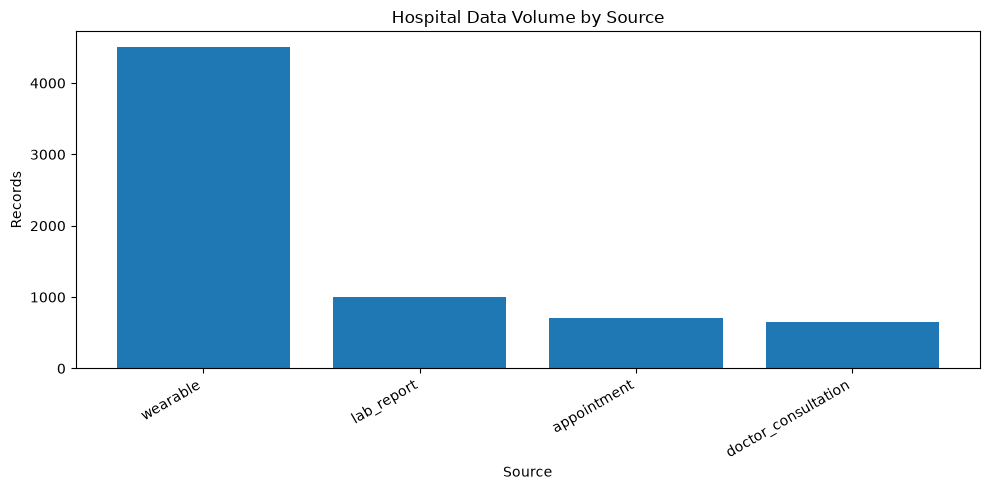

In [5]:
counts = clean_df["source_type"].value_counts()

plt.figure()
plt.bar(counts.index, counts.values)
plt.title("Hospital Data Volume by Source")
plt.xlabel("Source")
plt.ylabel("Records")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


## 6. Appointment Analytics — Waiting Time

,avg_wait_minutes,appointments,no_show_rate
department,,,
General Medicine,23.50,125,10.40
Pediatrics,23.38,118,11.86
Orthopedics,21.71,128,14.06
Cardiology,21.68,105,13.33
Emergency,21.23,106,11.32
Neurology,19.98,118,7.63


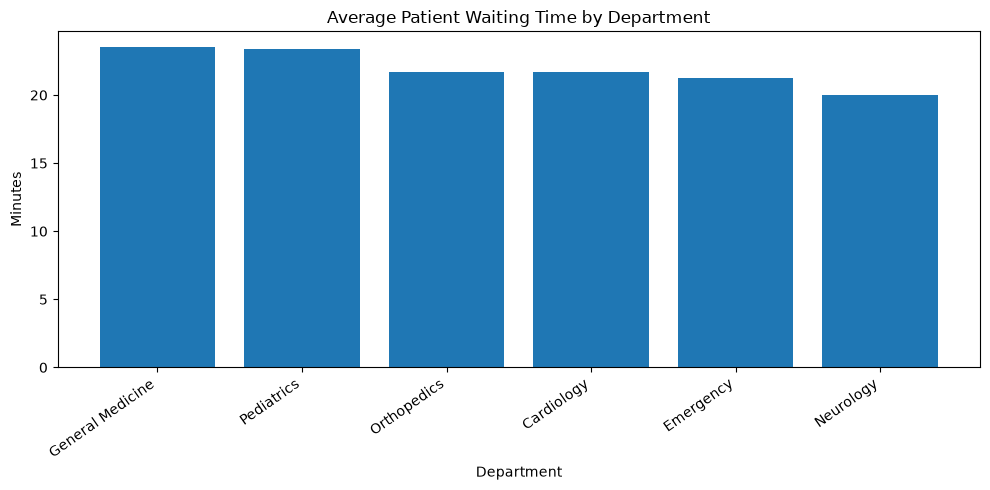

In [6]:
appt = clean_df[clean_df["source_type"] == "appointment"].copy()

wait_summary = appt.groupby("department").agg(
    avg_wait_minutes=("waiting_minutes","mean"),
    appointments=("record_id","count"),
    no_show_rate=("status", lambda x: (x == "No-show").mean()*100)
).sort_values("avg_wait_minutes", ascending=False)

display(wait_summary.round(2))

plt.figure()
plt.bar(wait_summary.index, wait_summary["avg_wait_minutes"])
plt.title("Average Patient Waiting Time by Department")
plt.xlabel("Department")
plt.ylabel("Minutes")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


## 7. Daily Appointment Volume

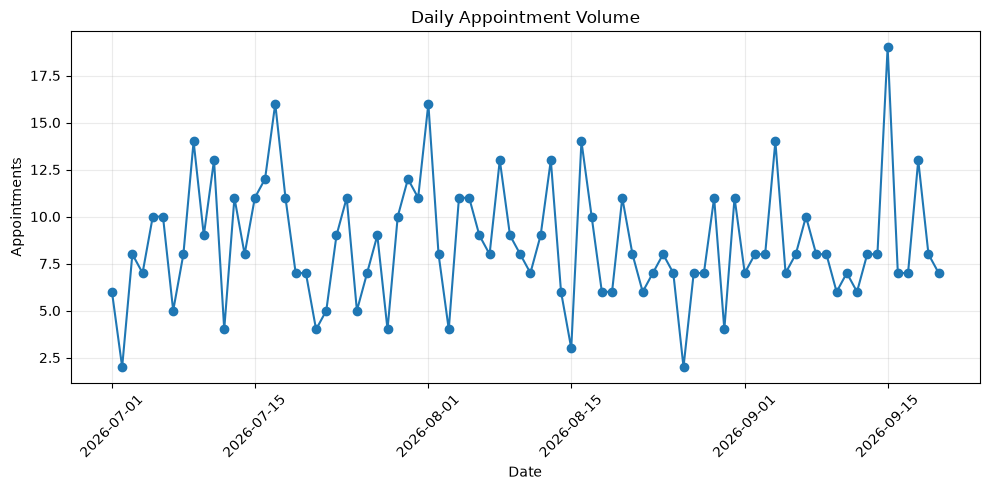

In [7]:
daily = appt.groupby(appt["event_date"].dt.date).size()

plt.figure()
plt.plot(daily.index, daily.values, marker="o", linewidth=1.5)
plt.title("Daily Appointment Volume")
plt.xlabel("Date")
plt.ylabel("Appointments")
plt.xticks(rotation=45)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 8. Laboratory Analytics

,tests,abnormal_rate,abnormal_rate_pct
test_name,,,
Cholesterol,144,0.24,24.31
Creatinine,179,0.28,27.93
Glucose,160,0.28,27.50
Hemoglobin,183,0.21,21.31
Platelets,169,0.15,14.79
WBC,165,0.19,19.39


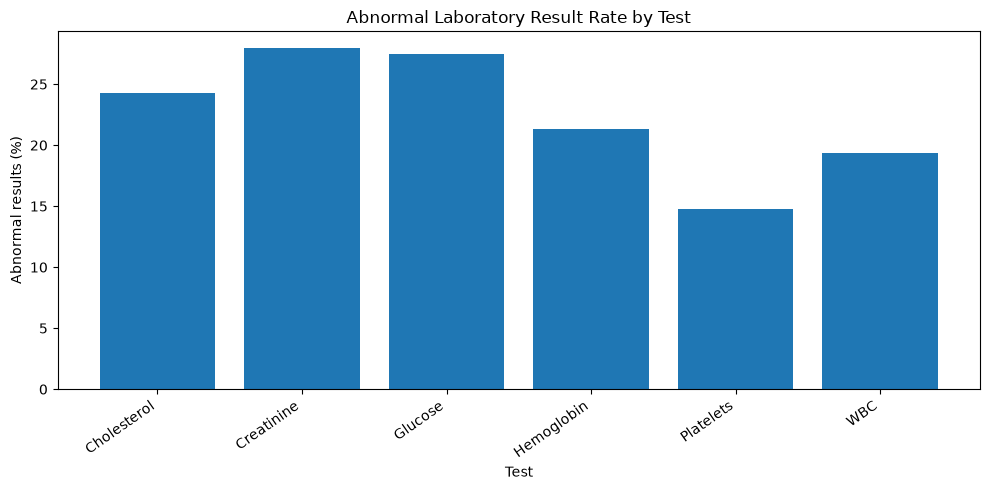

In [8]:
lab = clean_df[clean_df["source_type"] == "lab_report"].copy()
lab["is_abnormal"] = (lab["abnormal_flag"] == "Abnormal").astype(int)

lab_summary = lab.groupby("test_name").agg(
    tests=("record_id","count"),
    abnormal_rate=("is_abnormal","mean")
)
lab_summary["abnormal_rate_pct"] = lab_summary["abnormal_rate"]*100
display(lab_summary.round(2))

plt.figure()
plt.bar(lab_summary.index, lab_summary["abnormal_rate_pct"])
plt.title("Abnormal Laboratory Result Rate by Test")
plt.xlabel("Test")
plt.ylabel("Abnormal results (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


## 9. Wearable / IoT Analytics

,avg_heart_rate,min_spo2,avg_temperature,avg_steps
date,,,,
2026-07-01,82.389831,93.0,98.428814,6195.389831
2026-07-02,80.744186,93.0,98.402326,5813.581395
2026-07-03,81.377358,93.0,98.201887,6253.698113
2026-07-04,82.673469,94.0,98.463265,6082.367347
2026-07-05,79.877193,92.0,98.507018,6255.105263


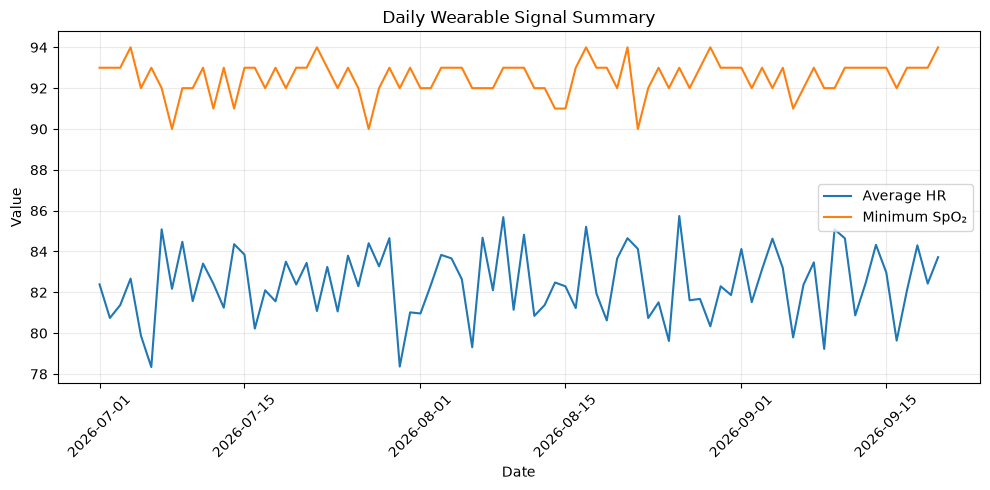

In [9]:
wear = clean_df[clean_df["source_type"] == "wearable"].copy()
wear["date"] = wear["event_date"].dt.date

wear_daily = wear.groupby("date").agg(
    avg_heart_rate=("heart_rate_bpm","mean"),
    min_spo2=("spo2_percent","min"),
    avg_temperature=("temperature_f","mean"),
    avg_steps=("steps","mean")
)

display(wear_daily.head())

plt.figure()
plt.plot(wear_daily.index, wear_daily["avg_heart_rate"], label="Average HR")
plt.plot(wear_daily.index, wear_daily["min_spo2"], label="Minimum SpO₂")
plt.title("Daily Wearable Signal Summary")
plt.xlabel("Date")
plt.ylabel("Value")
plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 10. Doctor Consultation Analytics

,consultations
symptom_severity,
Low,241
Moderate,242
High,130
Critical,37


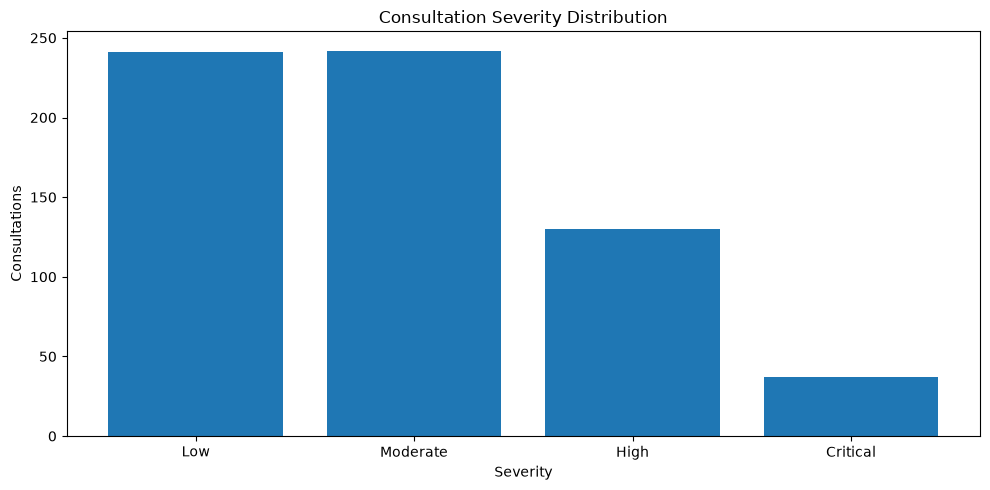

In [10]:
consult = clean_df[clean_df["source_type"] == "doctor_consultation"].copy()
order = ["Low","Moderate","High","Critical"]
severity = consult["symptom_severity"].value_counts().reindex(order).fillna(0)

display(severity.to_frame("consultations"))

plt.figure()
plt.bar(severity.index, severity.values)
plt.title("Consultation Severity Distribution")
plt.xlabel("Severity")
plt.ylabel("Consultations")
plt.tight_layout()
plt.show()


## 11. Build Patient 360

In [11]:
patient_base = clean_df[
    ["patient_id","age","gender","blood_group","city","chronic_condition","high_risk"]
].drop_duplicates("patient_id")

appt_features = appt.groupby("patient_id").agg(
    appointment_count=("record_id","count"),
    avg_wait_minutes=("waiting_minutes","mean"),
    no_show_count=("status", lambda x: (x=="No-show").sum())
).reset_index()

lab_features = lab.groupby("patient_id").agg(
    lab_test_count=("record_id","count"),
    abnormal_lab_count=("is_abnormal","sum")
).reset_index()
lab_features["abnormal_lab_rate"] = lab_features["abnormal_lab_count"] / lab_features["lab_test_count"]

wear_features = wear.groupby("patient_id").agg(
    avg_heart_rate=("heart_rate_bpm","mean"),
    min_spo2=("spo2_percent","min"),
    avg_temperature=("temperature_f","mean"),
    avg_steps=("steps","mean")
).reset_index()

severity_map = {"Low":0,"Moderate":1,"High":2,"Critical":3}
consult["severity_score"] = consult["symptom_severity"].map(severity_map)
consult_features = consult.groupby("patient_id").agg(
    consultation_count=("record_id","count"),
    max_severity=("severity_score","max")
).reset_index()

patient_360 = (
    patient_base
    .merge(appt_features,on="patient_id",how="left")
    .merge(lab_features,on="patient_id",how="left")
    .merge(wear_features,on="patient_id",how="left")
    .merge(consult_features,on="patient_id",how="left")
)

num_cols = patient_360.select_dtypes(include=np.number).columns
patient_360[num_cols] = patient_360[num_cols].fillna(0)

display(patient_360.head(10))
print("Patient 360 rows:", len(patient_360))


,patient_id,age,gender,blood_group,city,chronic_condition,high_risk,appointment_count,avg_wait_minutes,no_show_count,lab_test_count,abnormal_lab_count,abnormal_lab_rate,avg_heart_rate,min_spo2,avg_temperature,avg_steps,consultation_count,max_severity
0,P1207,83,Female,O-,Nellore,<NA>,0,7.0,19.714286,1.0,3.0,0.0,0.000000,85.000000,94.0,98.354167,6720.875000,3.0,2.0
1,P1160,85,Male,O+,Vijayawada,Hypertension,1,2.0,12.500000,0.0,7.0,1.0,0.142857,80.437500,94.0,98.200000,7218.187500,3.0,1.0
2,P1299,6,Female,AB+,Nellore,<NA>,0,2.0,14.500000,0.0,2.0,0.0,0.000000,81.733333,95.0,98.766667,6504.533333,1.0,0.0
3,P1231,74,Female,AB-,Guntur,Hypertension,0,4.0,20.750000,0.0,6.0,2.0,0.333333,83.705882,94.0,98.576471,4853.941176,2.0,1.0
4,P1005,74,Female,AB-,Nellore,<NA>,1,2.0,27.000000,0.0,0.0,0.0,0.000000,79.666667,94.0,98.486667,5955.666667,2.0,2.0
5,P1113,42,Male,B+,Nellore,Diabetes,1,5.0,26.800000,0.0,5.0,0.0,0.000000,81.812500,94.0,99.000000,6404.000000,4.0,2.0
6,P1086,12,Male,AB+,Nellore,Hypertension,0,4.0,22.750000,1.0,7.0,1.0,0.142857,82.117647,95.0,98.800000,6276.941176,3.0,1.0
7,P1176,63,Female,AB-,Nellore,<NA>,0,3.0,17.000000,1.0,1.0,0.0,0.000000,81.666667,94.0,98.366667,5468.666667,2.0,3.0
8,P1079,59,Male,AB+,Nellore,<NA>,0,3.0,16.000000,0.0,5.0,2.0,0.400000,87.000000,94.0,98.662500,6011.500000,2.0,1.0
9,P1289,43,Female,A+,Mangalagiri,<NA>,0,2.0,16.000000,1.0,6.0,1.0,0.166667,79.187500,94.0,98.725000,6158.375000,2.0,1.0


Patient 360 rows: 300


## 12. KPI Dashboard

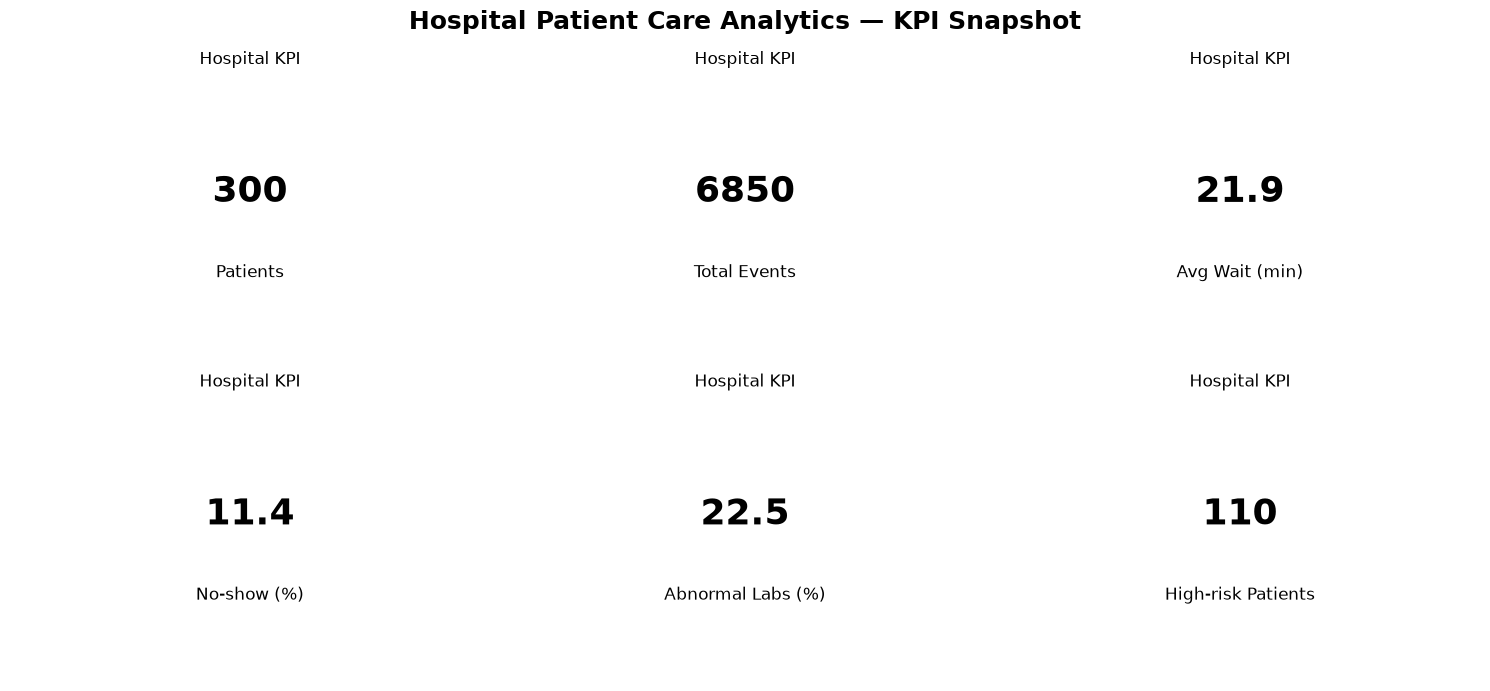

In [12]:
kpis = {
    "Patients": patient_360["patient_id"].nunique(),
    "Total Events": len(clean_df),
    "Avg Wait (min)": round(appt["waiting_minutes"].mean(),1),
    "No-show (%)": round((appt["status"]=="No-show").mean()*100,1),
    "Abnormal Labs (%)": round(lab["is_abnormal"].mean()*100,1),
    "High-risk Patients": int(patient_360["high_risk"].sum())
}

fig, axes = plt.subplots(2,3,figsize=(15,7))
for ax,(label,value) in zip(axes.ravel(),kpis.items()):
    ax.axis("off")
    ax.text(0.5,0.58,str(value),ha="center",va="center",fontsize=26,fontweight="bold")
    ax.text(0.5,0.30,label,ha="center",va="center",fontsize=12)
    ax.set_title("Hospital KPI")

plt.suptitle("Hospital Patient Care Analytics — KPI Snapshot",fontsize=18,fontweight="bold")
plt.tight_layout()
plt.show()


In [4]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

# ============================================================
# 1. Prepare model dataset
# ============================================================

model_df = patient_360[[
    "age",
    "gender",
    "chronic_condition",
    "abnormal_lab_rate",
    "avg_heart_rate",
    "min_spo2",
    "avg_temperature",
    "avg_wait_minutes",
    "appointment_count",
    "max_severity",
    "high_risk"
]].copy()

# ============================================================
# 2. Standardize missing values
# ============================================================

model_df = model_df.replace({
    pd.NA: np.nan,
    "": np.nan,
    "NA": np.nan,
    "N/A": np.nan,
    "null": np.nan,
    "None": np.nan
})

# ============================================================
# 3. Define features
# ============================================================

numeric_features = [
    "age",
    "abnormal_lab_rate",
    "avg_heart_rate",
    "min_spo2",
    "avg_temperature",
    "avg_wait_minutes",
    "appointment_count",
    "max_severity"
]

categorical_features = [
    "gender",
    "chronic_condition"
]

# ============================================================
# 4. Convert numeric columns
# ============================================================

for col in numeric_features:
    model_df[col] = pd.to_numeric(
        model_df[col],
        errors="coerce"
    )

# ============================================================
# 5. Clean categorical columns
# ============================================================

for col in categorical_features:
    model_df[col] = model_df[col].astype("object")

# ============================================================
# 6. Convert high-risk target
# ============================================================

# Handles both 0/1 and Yes/No style labels

if model_df["high_risk"].dtype == "object":

    model_df["high_risk"] = (
        model_df["high_risk"]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({
            "yes": 1,
            "no": 0,
            "high": 1,
            "low": 0,
            "true": 1,
            "false": 0,
            "1": 1,
            "0": 0
        })
    )

else:
    model_df["high_risk"] = pd.to_numeric(
        model_df["high_risk"],
        errors="coerce"
    )

# ============================================================
# 7. Remove rows with missing target
# ============================================================

model_df = model_df.dropna(
    subset=["high_risk"]
)

model_df["high_risk"] = model_df[
    "high_risk"
].astype(int)

# ============================================================
# 8. Separate X and y
# ============================================================

X = model_df.drop(
    columns=["high_risk"]
)

y = model_df["high_risk"]

print("Dataset shape:", model_df.shape)
print("\nRisk distribution:")
print(y.value_counts())

# ============================================================
# 9. Train-test split
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

# ============================================================
# 10. Preprocessing pipeline
# ============================================================

preprocessor = ColumnTransformer([

    # Numerical data
    (
        "num",
        Pipeline([
            (
                "imputer",
                SimpleImputer(strategy="median")
            ),
            (
                "scaler",
                StandardScaler()
            )
        ]),
        numeric_features
    ),

    # Categorical data
    (
        "cat",
        Pipeline([
            (
                "imputer",
                SimpleImputer(strategy="most_frequent")
            ),
            (
                "onehot",
                OneHotEncoder(
                    handle_unknown="ignore"
                )
            )
        ]),
        categorical_features
    )
])

# ============================================================
# 11. Logistic Regression model
# ============================================================

model = Pipeline([

    (
        "preprocessor",
        preprocessor
    ),

    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

# ============================================================
# 12. Train
# ============================================================

model.fit(
    X_train,
    y_train
)

print("\nModel training completed successfully.")

# ============================================================
# 13. Predictions
# ============================================================

pred = model.predict(X_test)

prob = model.predict_proba(
    X_test
)[:, 1]

# ============================================================
# 14. Evaluation
# ============================================================

print("\n" + "=" * 60)
print("MODEL EVALUATION")
print("=" * 60)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        pred,
        digits=3
    )
)

roc_auc = roc_auc_score(
    y_test,
    prob
)

print(
    f"ROC-AUC: {roc_auc:.3f}"
)

print("\nModel evaluation completed.")

NameError: name 'patient_360' is not defined

## 13. Synthetic High-Risk Prediction

This section demonstrates the final ML stage of the data engineering pipeline.

**Patient 360 → Feature Engineering → Preprocessing → Logistic Regression → Evaluation**

The target is synthetic and is not a clinical prediction.


In [2]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

# --------------------------------------------------
# 1. Select features for the risk prediction model
# --------------------------------------------------

model_df = patient_360[[
    "age",
    "gender",
    "chronic_condition",
    "abnormal_lab_rate",
    "avg_heart_rate",
    "min_spo2",
    "avg_temperature",
    "avg_wait_minutes",
    "appointment_count",
    "max_severity",
    "high_risk"
]].copy()

# --------------------------------------------------
# 2. Convert pandas nullable values to standard NaN
# --------------------------------------------------

model_df = model_df.replace({pd.NA: np.nan})

# Convert numeric columns explicitly
numeric_features = [
    "age",
    "abnormal_lab_rate",
    "avg_heart_rate",
    "min_spo2",
    "avg_temperature",
    "avg_wait_minutes",
    "appointment_count",
    "max_severity"
]

for col in numeric_features:
    model_df[col] = pd.to_numeric(
        model_df[col],
        errors="coerce"
    )

# Convert categorical columns to string/object
categorical_features = [
    "gender",
    "chronic_condition"
]

for col in categorical_features:
    model_df[col] = model_df[col].astype("object")

# --------------------------------------------------
# 3. Separate features and target
# --------------------------------------------------

X = model_df.drop(columns="high_risk")
y = pd.to_numeric(
    model_df["high_risk"],
    errors="coerce"
)

# Remove rows where target is missing
valid_rows = y.notna()

X = X.loc[valid_rows]
y = y.loc[valid_rows].astype(int)

# --------------------------------------------------
# 4. Train-test split
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# --------------------------------------------------
# 5. Preprocessing
# --------------------------------------------------

preprocessor = ColumnTransformer([
    
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(
            strategy="most_frequent"
        )),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore"
        ))
    ]), categorical_features)
])

# --------------------------------------------------
# 6. Logistic Regression Pipeline
# --------------------------------------------------

model = Pipeline([
    ("preprocessor", preprocessor),

    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

# --------------------------------------------------
# 7. Train model
# --------------------------------------------------

model.fit(X_train, y_train)

# --------------------------------------------------
# 8. Predictions
# --------------------------------------------------

pred = model.predict(X_test)

prob = model.predict_proba(X_test)[:, 1]

# --------------------------------------------------
# 9. Evaluation
# --------------------------------------------------

print("Classification Report:")
print(classification_report(
    y_test,
    pred,
    digits=3
))

print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, prob), 3)
)

NameError: name 'patient_360' is not defined

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_test,pred)
plt.title("Synthetic High-Risk Classification — Confusion Matrix")
plt.tight_layout()
plt.show()

RocCurveDisplay.from_predictions(y_test,prob)
plt.title("Synthetic High-Risk Classification — ROC Curve")
plt.tight_layout()
plt.show()


## 14. Final Key Points

### Data Engineering
- Single integrated landing dataset
- Data quality validation
- Cleaning and standardization
- Patient 360 aggregation
- KPI-ready analytical layer

### Hospital Operations
- Waiting-time analysis
- Appointment volume monitoring
- No-show analysis
- Department-level performance

### Clinical Analytics Demonstration
- Lab abnormality trends
- Wearable signal aggregation
- Consultation severity analysis
- Synthetic risk classification

### Production Technologies

```text
Sources
  ↓
Kafka / Kinesis / APIs
  ↓
S3 / Data Lake
  ↓
Spark / Databricks
  ↓
Airflow
  ↓
Redshift / Snowflake / BigQuery
  ↓
Power BI / Tableau / QuickSight
  ↓
ML Platform
```
